# Exp 7 – SVM Classifier | Validation-Based Threshold Optimization

1. Missing categorical values are imputed using the most frequent value, followed by One-Hot Encoding (OHE).
2. Missing numerical values are imputed using the median, followed by StandardScaler.
3. Class imbalance is handled using class_weight='balanced'.
4. The original training data is split into model training (80%) and validation (20%), keeping the test set untouched.
5. RandomizedSearchCV with 5-Fold Stratified CV and 25 iterations is used to tune Linear and RBF SVM hyperparameters based on PR-AUC.
6. The best model generates churn probabilities on the validation set.
7. Validation probabilities are used to select the best classification threshold based on F1 Score.
8. The best model is retrained on the complete training dataset using the selected threshold.
9. The selected threshold is applied to training, validation, and test probabilities to generate:
   0 = Retained | 1 = Churned.
10. Model performance is evaluated using classification metrics, confusion matrix, and diagnostic cross-validation.

## 0. IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid')

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

## 1. SEPARATE FEATURES AND TARGET

In [3]:
date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']
X = df.drop(columns=['id', 'churn'] + date_cols, errors='ignore').copy()
y = df['churn'].copy()

print("Dataset Shape:", X.shape)
print("Total Missing Values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Dataset Shape: (14606, 104)
Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


## 2. TRAIN TEST SPLIT

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)


Original Training Data: (11684, 104)
Original Test Data: (2922, 104)


## 3. MODEL TRAINING AND THRESHOLD VALIDATION SPLIT

In [5]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=21, stratify=y_train
)
print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)
print("Final Test Data:", X_test.shape)


Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)
Final Test Data: (2922, 104)


## 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS

In [6]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))


Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101


## 5. PREPROCESSING PIPELINE

In [7]:
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_pipeline, categorical_cols),
        ('num', numerical_pipeline, numerical_cols)
    ],
    remainder='drop',
    n_jobs=1
)

## 6. SVM PIPELINE

In [8]:
svm_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', SVC(
        class_weight='balanced',
        probability=True,
        random_state=42,
        cache_size=500
    ))
])

## 7. STRATIFIED CROSS VALIDATION

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 8. HYPERPARAMETER SEARCH SPACE

In [10]:
param_grid = [
    {
        'model__kernel': ['linear'],
        'model__C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'model__kernel': ['rbf'],
        'model__C': [0.1, 1, 10, 100],
        'model__gamma': ['scale', 'auto', 0.001, 0.01, 0.1]
    }
]

## 9. RANDOMIZED SEARCH CV

In [11]:
random_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

## 10. FIT RANDOMIZED SEARCH

In [12]:
random_search.fit(X_fit, y_fit)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"[{'model__C': [0.01, 0.1, ...], 'model__kernel': ['linear']}, {'model__C': [0.1, 1, ...], 'model__gamma': ['scale', 'auto', ...], 'model__kernel': ['rbf']}]"
,n_iter,25
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


## 11. BEST HYPERPARAMETERS

In [13]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))


==== BEST HYPERPARAMETERS ====
{'model__kernel': 'rbf', 'model__gamma': 0.001, 'model__C': 100}

Best CV PR-AUC: 0.2085


## 12. BEST SVM MODEL

In [14]:
best_svm_pipeline = random_search.best_estimator_

## 13. RANDOMIZED SEARCH RESULTS

In [15]:
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score', ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(
    search_results_df[
        [
            'param_model__kernel',
            'param_model__C',
            'param_model__gamma',
            'mean_test_score',
            'std_test_score'
        ]
    ].head(10).round(4).to_string(index=False)
)


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
param_model__kernel  param_model__C param_model__gamma  mean_test_score  std_test_score
                rbf           100.0              0.001           0.2085          0.0271
                rbf            10.0              scale           0.2042          0.0264
                rbf            10.0               0.01           0.2039          0.0270
                rbf             1.0               auto           0.2030          0.0320
                rbf            10.0               auto           0.2026          0.0241
                rbf             1.0               0.01           0.2026          0.0305
                rbf            10.0              0.001           0.2024          0.0309
                rbf             1.0              scale           0.2023          0.0306
                rbf           100.0              scale           0.1945          0.0167
                rbf           100.0               0.01           0.1940   

## 14. VALIDATION PROBABILITIES

In [16]:
y_prob_val = best_svm_pipeline.predict_proba(X_val)[:, 1]

## 15. PRECISION RECALL CURVE

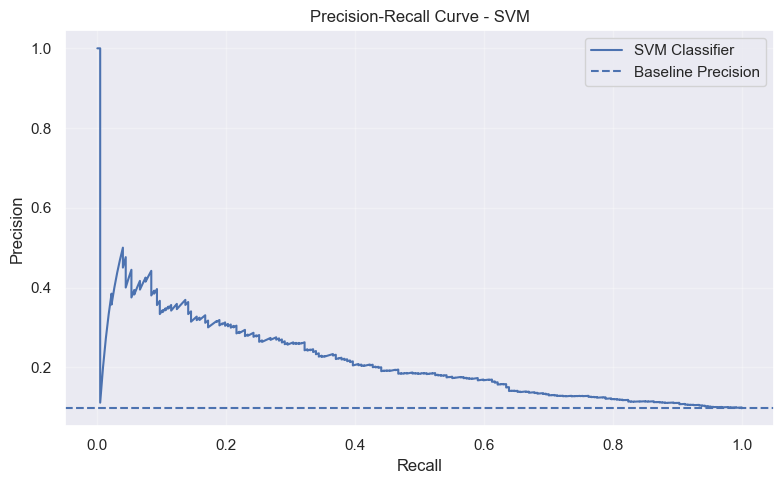

In [17]:
precision, recall, pr_thresholds = precision_recall_curve(y_val, y_prob_val)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label='SVM Classifier')
plt.axhline(
    y=y_val.mean(), linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - SVM')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 16. FINE-GRAINED THRESHOLD ANALYSIS

In [18]:
threshold_values = np.arange(0.05, 0.96, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)
    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1001  0.9604    0.1814
      0.06     0.1041  0.9383    0.1873
      0.07     0.1126  0.8678    0.1993
      0.08     0.1240  0.7841    0.2142
      0.09     0.1350  0.6828    0.2255
      0.10     0.1604  0.6211    0.2550
      0.11     0.1789  0.5374    0.2684
      0.12     0.1927  0.4405    0.2681
      0.13     0.2240  0.3789    0.2815
      0.14     0.2609  0.3172    0.2863
      0.15     0.2772  0.2467    0.2611
      0.16     0.3061  0.1982    0.2406
      0.17     0.3208  0.1498    0.2042
      0.18     0.3562  0.1145    0.1733
      0.19     0.3846  0.0881    0.1434
      0.20     0.3947  0.0661    0.1132
      0.21     0.4000  0.0529    0.0934
      0.22     0.4545  0.0441    0.0803
      0.23     0.5000  0.0396    0.0735
      0.24     0.3571  0.0220    0.0415
      0.25     0.3571  0.0220    0.0415
      0.26     0.3846  0.0220    0.0417
      0.27     0.1111  0.0044    0.00

## 17. THRESHOLD PERFORMANCE VISUALIZATION

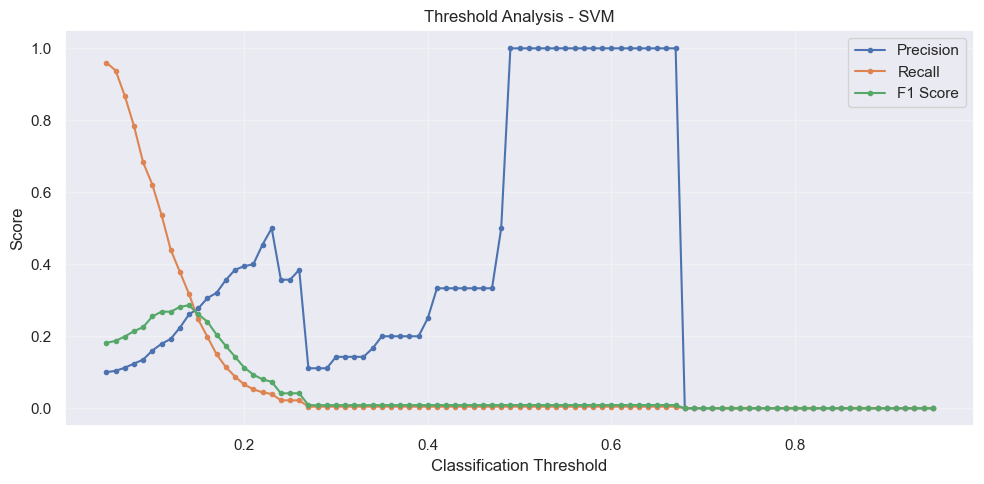

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o', markersize=3, label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o', markersize=3, label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o', markersize=3, label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - SVM')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 18. SELECT BEST THRESHOLD

In [20]:
best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(), 'Threshold'
]
print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", round(best_threshold, 2))
print(
    fine_threshold_df.loc[
        fine_threshold_df['F1 Score'].idxmax()
    ].round(4)
)


==== BEST THRESHOLD ====
Best Threshold: 0.14
Threshold    0.1400
Precision    0.2609
Recall       0.3172
F1 Score     0.2863
Name: 9, dtype: float64


## 19. RETRAIN BEST MODEL ON COMPLETE TRAINING DATA

In [21]:
final_svm_pipeline = clone(best_svm_pipeline)
final_svm_pipeline.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,1
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 20. TRAIN PREDICTIONS

In [22]:
y_prob_train = final_svm_pipeline.predict_proba(X_train)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

## 21. VALIDATION PREDICTIONS

In [23]:
# Validation predictions use the model trained on X_fit.
y_pred_val = (y_prob_val >= best_threshold).astype(int)

## 22. TEST PREDICTIONS

In [24]:
y_prob_test = final_svm_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

## 23. DEFINE METRIC FUNCTION

In [25]:
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

## 24. TRAIN, VALIDATION AND TEST METRICS

In [26]:
train_metrics = calc_metrics(y_train, y_pred_train, y_prob_train)
val_metrics = calc_metrics(y_val, y_pred_val, y_prob_val)
test_metrics = calc_metrics(y_test, y_pred_test, y_prob_test)

print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\n==== VALIDATION METRICS ====")
for metric, value in val_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.8506
Precision   : 0.3241
Recall      : 0.4960
F1 Score    : 0.3921
ROC-AUC     : 0.7853
PR-AUC      : 0.3174

==== VALIDATION METRICS ====
Accuracy    : 0.8464
Precision   : 0.2609
Recall      : 0.3172
F1 Score    : 0.2863
ROC-AUC     : 0.6708
PR-AUC      : 0.2140

==== TEST METRICS ====
Accuracy    : 0.8275
Precision   : 0.2368
Recall      : 0.3486
F1 Score    : 0.2821
ROC-AUC     : 0.6645
PR-AUC      : 0.2013


## 25. CONFUSION MATRIX

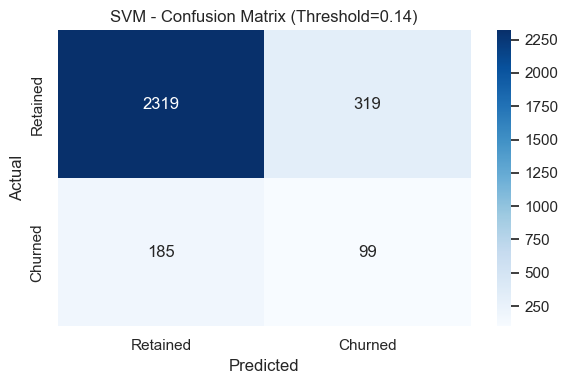

In [27]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'SVM - Confusion Matrix (Threshold={best_threshold:.2f})')
plt.tight_layout()
plt.show()

## 26. CLASSIFICATION REPORT

In [28]:
print("\n==== CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.88      0.90      2638
     Churned       0.24      0.35      0.28       284

    accuracy                           0.83      2922
   macro avg       0.58      0.61      0.59      2922
weighted avg       0.86      0.83      0.84      2922



## 27. CROSS VALIDATION PERFORMANCE

In [29]:
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

# Diagnostic CV on X_fit only.
# These scores are not an independent estimate after hyperparameter tuning.
cv_results = cross_validate(
    best_svm_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

## 28. CROSS VALIDATION TRAIN SCORES

In [30]:
print("\n==== CV TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CV TRAIN SCORES ====
train_Accuracy - Mean: 0.7326, Std: 0.0111
train_Precision - Mean: 0.2237, Std: 0.0076
train_Recall - Mean: 0.7079, Std: 0.0135
train_F1 - Mean: 0.3398, Std: 0.0087
train_ROC_AUC - Mean: 0.7972, Std: 0.0044
train_PR_AUC - Mean: 0.3287, Std: 0.0135


## 29. CROSS VALIDATION VALIDATION SCORES

In [31]:
print("\n==== CV VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CV VALIDATION SCORES ====
test_Accuracy - Mean: 0.6967, Std: 0.0126
test_Precision - Mean: 0.1648, Std: 0.0054
test_Recall - Mean: 0.5220, Std: 0.0407
test_F1 - Mean: 0.2503, Std: 0.0101
test_ROC_AUC - Mean: 0.6544, Std: 0.0202
test_PR_AUC - Mean: 0.2085, Std: 0.0271


## 30. FINAL EXPERIMENT SUMMARY

In [32]:
print("\n" + "=" * 50)
print("SVM CLASSIFIER - EXPERIMENT COMPLETED")
print("=" * 50)
print("Best Kernel:", random_search.best_params_['model__kernel'])
print("Best C:", random_search.best_params_['model__C'])
print("Best Threshold:", round(best_threshold, 2))
print("Best CV PR-AUC:", round(random_search.best_score_, 4))
print("Test PR-AUC:", round(test_metrics['PR-AUC'], 4))
print("Test Recall:", round(test_metrics['Recall'], 4))
print("Test Precision:", round(test_metrics['Precision'], 4))
print("Test F1 Score:", round(test_metrics['F1 Score'], 4))


SVM CLASSIFIER - EXPERIMENT COMPLETED
Best Kernel: rbf
Best C: 100
Best Threshold: 0.14
Best CV PR-AUC: 0.2085
Test PR-AUC: 0.2013
Test Recall: 0.3486
Test Precision: 0.2368
Test F1 Score: 0.2821


# Observation: **Exp 7 – SVM Classifier | Validation-Based Threshold Optimization**

**1. Model Optimization**

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `kernel`: rbf
  - `C`: 100
  - `gamma`: 0.001
- Best CV PR-AUC: **20.85%**

**Observation:**

- RBF kernel was selected as the best configuration.
- CV PR-AUC is lower than all previous experiments.
- SVM struggles to distinguish churn and retained customers effectively.

**2. Model Performance – Test Data**

- Accuracy: **82.75%**
- Precision: **23.68%**
- Recall: **34.86%**
- F1 Score: **28.21%**
- ROC-AUC: **66.45%**
- PR-AUC: **20.13%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.14**, based on the highest F1 score in the threshold analysis.
- At threshold 0.14 (threshold validation):
  - Precision: 26.09%
  - Recall: 31.72%
  - F1 Score: 28.63%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.14)**

- True Negatives: 2,319
- False Positives: 319
- False Negatives: 185
- True Positives: 99

**Observation:**

- Model correctly identifies 99 churn customers out of 284.
- It misses 185 actual churn customers.
- False positives are relatively high (319).

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 20.13% is considerably lower than previous experiments.

**6. Cross-Validation Results**

- Training PR-AUC: 32.87%
- Validation accuracy: 69.67%
- Validation precision: 16.48%
- Validation recall: 52.20%
- Validation F1: 25.03%
- Validation ROC-AUC: 65.44%
- Validation PR-AUC: 20.85%

**Observation:**

- Training and validation PR-AUC are relatively close.
- However, overall validation performance is weak.
- Validation recall is better than several previous models, but precision is very low.
- SVM identifies more potential churn customers at the cost of more false positives.

**7. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB | Exp6-LightGBM | Exp7-SVM |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- | ------------- | -------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 | 88.02%        | 82.75%   |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 | 36.48%        | 23.68%   |
| Recall    | 36.97%           | 34.86%              | **38.73%**            | 28.52%       | 32.39%                 | 31.34%        | 34.86%   |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 | 33.71%        | 28.21%   |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 | 69.33%        | 66.45%   |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 | 32.20%        | 20.13%   |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 | 28.63%        | 20.85%   |

**Observation:**

- SVM achieves the lowest test PR-AUC (20.13%) among all experiments.
- Its precision (23.68%) and F1 Score (28.21%) are also the lowest.
- Recall (34.86%) is better than Exp4, Exp5 and Exp6.
- SVM does not provide a good overall balance between precision and recall.

**Final Conclusion – SVM Classifier**

- SVM achieves a test PR-AUC of only 20.13%.
- Although recall is 34.86%, precision is relatively low at 23.68%.
- Cross-validation and test PR-AUC are also lower than previous experiments.
- SVM does not improve overall churn prediction performance.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Regularized Random Forest remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%). It provides a better balance between identifying churn customers and controlling false positives.

SVM is currently the weakest model based on PR-AUC and F1 Score.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.14 threshold. Compare classification metrics cautiously.

# Note: Final Model Selection and Further Experiments

Based on the initial experiments, Exp2 (Regularized Random Forest) and Exp4 (XGBoost) were selected for further investigation.

From this point onward, the experiments will focus on improving these two models through:
- Outlier detection and treatment.
- Log transformations to reduce feature skewness.
- Further model optimization and performance evaluation.

The objective is to improve churn detection, reduce overfitting, and achieve better generalization on unseen data.